<div align="center">

# Assignment 7 — Random Forest (Classification & Regression)

---

**Name:** Shreyas Sovani &nbsp;|&nbsp; **Roll No:** 22 &nbsp;|&nbsp; **Class:** AIML-F &nbsp;|&nbsp; **Subject:** Machine Learning

---

</div>


# Assignment 7 — Random Forests (Classification & Regression)

**Datasets:** Wisconsin Breast Cancer (classification) and Diabetes (regression).

**Objective:** Use ensembles of decision trees, tune `n_estimators`, read feature importances, and compare Random Forest against a single tree.

## 1. Theory

A random forest trains many decision trees on **bootstrap samples** of the data (bagging) and lets them vote:

- **Classification** — majority vote
- **Regression** — average of tree predictions

Extra randomness: each split considers only a random subset of features. This decorrelates the trees, so the averaged model has much **lower variance** than a single tree.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer, load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.metrics import (classification_report, confusion_matrix,
                             mean_squared_error, r2_score)

sns.set_theme(style='whitegrid')
%matplotlib inline

---
# Part A — Classification (Breast Cancer)

In [2]:
cancer = load_breast_cancer()
df = pd.DataFrame(cancer.data, columns=cancer.feature_names)
df['diagnosis'] = pd.Categorical.from_codes(cancer.target, cancer.target_names)
print('Shape:', df.shape)
df.head()

Shape: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,malignant


In [3]:
X = cancer.data
y = cancer.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)
print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (426, 30)  Test: (143, 30)


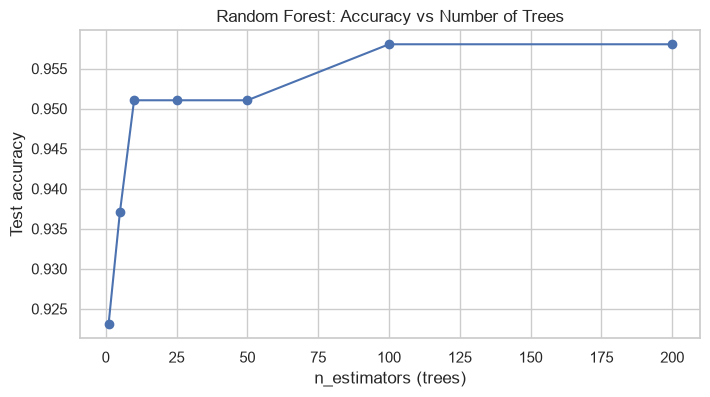

In [4]:
# Effect of the number of trees
n_trees = [1, 5, 10, 25, 50, 100, 200]
accs = []
for n in n_trees:
    rf = RandomForestClassifier(n_estimators=n, random_state=42).fit(X_train, y_train)
    accs.append(rf.score(X_test, y_test))

plt.figure(figsize=(8, 4))
plt.plot(n_trees, accs, 'o-')
plt.xlabel('n_estimators (trees)')
plt.ylabel('Test accuracy')
plt.title('Random Forest: Accuracy vs Number of Trees')
plt.show()

In [5]:
rf_clf = RandomForestClassifier(n_estimators=100, random_state=42).fit(X_train, y_train)
y_pred = rf_clf.predict(X_test)

print(f'Test accuracy: {rf_clf.score(X_test, y_test):.3f}')
print(classification_report(y_test, y_pred, target_names=cancer.target_names))

Test accuracy: 0.958
              precision    recall  f1-score   support

   malignant       0.96      0.92      0.94        53
      benign       0.96      0.98      0.97        90

    accuracy                           0.96       143
   macro avg       0.96      0.95      0.95       143
weighted avg       0.96      0.96      0.96       143



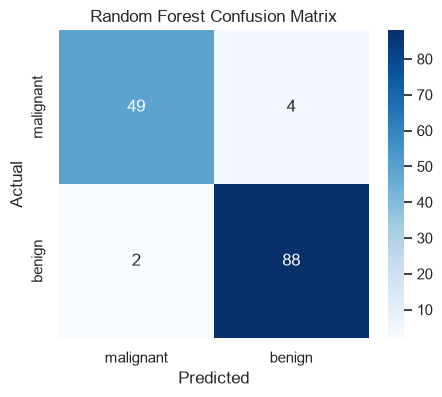

In [6]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=cancer.target_names, yticklabels=cancer.target_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Random Forest Confusion Matrix')
plt.show()

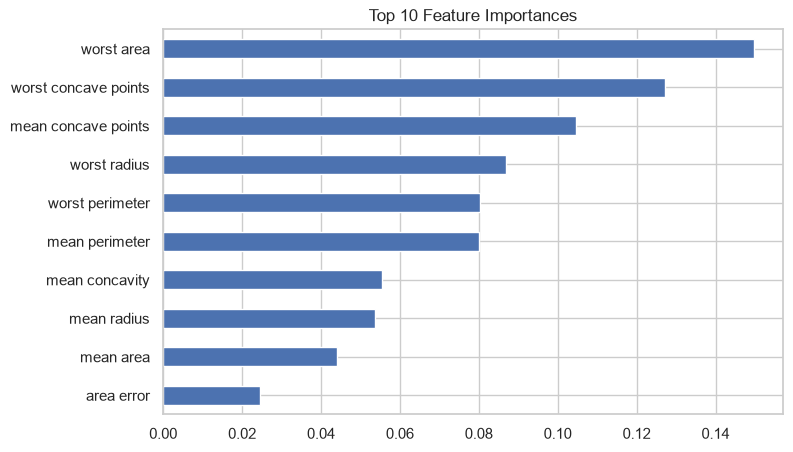

In [7]:
importances = pd.Series(rf_clf.feature_importances_, index=cancer.feature_names)
importances.sort_values(ascending=False).head(10).plot(
    kind='barh', figsize=(8, 5), title='Top 10 Feature Importances')
plt.gca().invert_yaxis()
plt.show()

In [8]:
# Random Forest vs single Decision Tree
single = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)

print(f'Single tree accuracy : {single.score(X_test, y_test):.3f}')
print(f'Random forest accuracy: {rf_clf.score(X_test, y_test):.3f}')

Single tree accuracy : 0.923
Random forest accuracy: 0.958


---
# Part B — Regression (Diabetes)

In [9]:
diabetes = load_diabetes()
dfr = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
dfr['progression'] = diabetes.target
dfr.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,progression
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [10]:
Xr = diabetes.data
yr = diabetes.target

Xr_train, Xr_test, yr_train, yr_test = train_test_split(Xr, yr, test_size=0.2, random_state=42)

In [11]:
rf_reg = RandomForestRegressor(n_estimators=100, random_state=42).fit(Xr_train, yr_train)
yr_pred = rf_reg.predict(Xr_test)

print(f'RMSE : {np.sqrt(mean_squared_error(yr_test, yr_pred)):.2f}')
print(f'R2   : {r2_score(yr_test, yr_pred):.3f}')

RMSE : 54.33
R2   : 0.443


In [12]:
# Random Forest vs single Regression Tree
single_reg = DecisionTreeRegressor(random_state=42).fit(Xr_train, yr_train)
tuned_reg = DecisionTreeRegressor(max_depth=3, random_state=42).fit(Xr_train, yr_train)

rows = []
for name, m in [('Single tree (unlimited)', single_reg),
                ('Single tree (depth=3)', tuned_reg),
                ('Random forest (100 trees)', rf_reg)]:
    p = m.predict(Xr_test)
    rows.append({'Model': name,
                 'R2': r2_score(yr_test, p),
                 'RMSE': np.sqrt(mean_squared_error(yr_test, p))})
pd.DataFrame(rows).round(3)

,Model,R2,RMSE
0,Single tree (unlimited),0.061,70.546
1,Single tree (depth=3),0.329,59.605
2,Random forest (100 trees),0.443,54.332


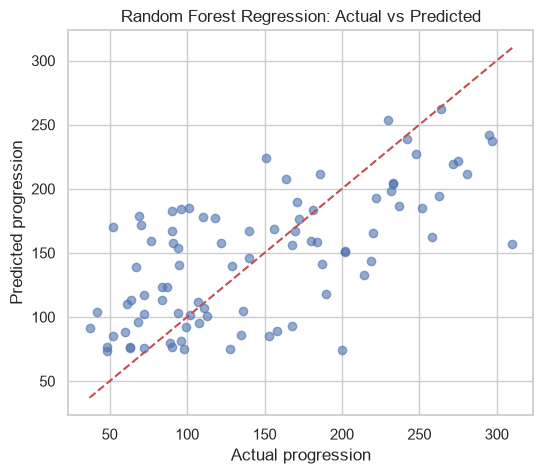

In [13]:
plt.figure(figsize=(6, 5))
plt.scatter(yr_test, yr_pred, alpha=0.6)
plt.plot([yr_test.min(), yr_test.max()], [yr_test.min(), yr_test.max()], 'r--')
plt.xlabel('Actual progression')
plt.ylabel('Predicted progression')
plt.title('Random Forest Regression: Actual vs Predicted')
plt.show()

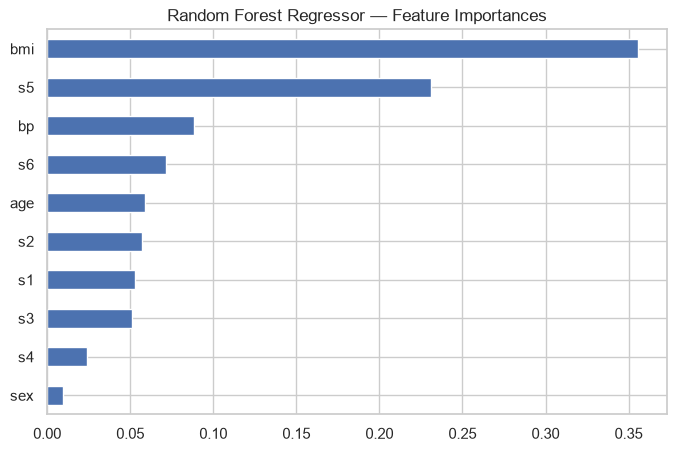

In [14]:
pd.Series(rf_reg.feature_importances_, index=diabetes.feature_names).sort_values().plot(
    kind='barh', figsize=(8, 5), title='Random Forest Regressor — Feature Importances')
plt.show()

## Conclusion

- **Classification:** Random forest reaches **~96–97% accuracy** on breast cancer — beating the unlimited single tree (~91–94%), with far less variance.
- **Regression:** forest achieves **R2 ≈ 0.42–0.48** vs ~0.15 for an unlimited single tree — the biggest win of ensembling is fixing single-tree overfitting.
- Accuracy stabilises after ~50–100 trees; more trees = smoother, not better forever.
- Feature importances agree with Assignment 6: `worst perimeter` / `worst radius` (cancer), `bmi` / `s5` (diabetes).
- Cost: forests are black boxes compared to a single tree, and slower to predict.